# Kapitel 6: Ergebnisse

### Export laden

In [1]:
import os
import json
from collections import Counter, defaultdict
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

PROJEKT = Path.cwd()
for _kandidat in [PROJEKT, *PROJEKT.parents]:
    if (_kandidat / "Korpus").is_dir() or (_kandidat / "prototyp_ergebnisse_alle.json").is_file():
        PROJEKT = _kandidat
        break
os.chdir(PROJEKT)

#Export laden
DATEI = Path("prototyp_ergebnisse_alle.json")
with open(DATEI, encoding="utf-8") as f:
    daten = json.load(f)

#Ausgabeordner für Abbildungen
AUSGABE = Path("ergebnisse_kapitel6")
AUSGABE.mkdir(exist_ok=True)

#Grundtabellen: eine Zeile je Märchen und eine Zeile je Adjektivbeleg
df_maerchen = pd.DataFrame(daten["korpus"]["maerchen"])
df_zuordnungen = pd.DataFrame(daten["adjektiv_zuordnungen_alle"])
SAMMLUNGEN = sorted(df_maerchen["sammlung"].unique())

zugeordnet = df_zuordnungen[df_zuordnungen["status"] == "zugeordnet"]
offen = df_zuordnungen[df_zuordnungen["status"] == "offen"]


def prozent(teil, ganzes):
    #Anteil in Prozent mit einer Nachkommastelle
    return round(100 * teil / ganzes, 1)


print("Export:", DATEI, "| Version:", daten["meta"]["notebook_version"])
print("Sammlungen:", ", ".join(SAMMLUNGEN))

Export: prototyp_ergebnisse_alle.json | Version: V1.0
Sammlungen: Arabische Märchen, Brüder Grimm, H. C. Andersen, Japanische Märchen


### 6.1 Überblick

Kennzahlen aus dem Text.

In [2]:
n_belege = len(df_zuordnungen)
n_coref = int((zugeordnet["methode"] == "coref").sum())

print("Märchen:", daten["korpus"]["anzahl_maerchen"],
      "| Sammlungen:", daten["korpus"]["anzahl_sammlungen"],
      "| fehlgeschlagen:", daten["korpus"]["anzahl_fehlgeschlagen"])
print("Sätze:", df_maerchen["saetze"].sum())
print("Adjektivbelege:", n_belege)
print("Zugeordnete Belege:", len(zugeordnet), "|", prozent(len(zugeordnet), n_belege), "%")
print("  unmittelbar (Originaltext):", len(zugeordnet) - n_coref)
print("  über Nachauflösung (Coref):", n_coref, "|",
      prozent(n_coref, len(zugeordnet)), "% der zugeordneten Belege")

Märchen: 80 | Sammlungen: 4 | fehlgeschlagen: 0
Sätze: 9252
Adjektivbelege: 11022
Zugeordnete Belege: 4254 | 38.6 %
  unmittelbar (Originaltext): 2898
  über Nachauflösung (Coref): 1356 | 31.9 % der zugeordneten Belege


**Tabelle 1:** Adjektive über Nachauflösung je Sammlung

In [3]:
tabelle1 = pd.DataFrame({
    "zugeordnete_belege": zugeordnet.groupby("sammlung").size(),
    "davon_nachaufloesung": zugeordnet[zugeordnet["methode"] == "coref"].groupby("sammlung").size(),
})
tabelle1.loc["Korpus"] = tabelle1.sum()
tabelle1["anteil_%"] = (100 * tabelle1["davon_nachaufloesung"] / tabelle1["zugeordnete_belege"]).round(1)
tabelle1

,zugeordnete_belege,davon_nachaufloesung,anteil_%
sammlung,,,
Arabische Märchen,1103,414,37.5
Brüder Grimm,1543,487,31.6
H. C. Andersen,1056,250,23.7
Japanische Märchen,552,205,37.1
Korpus,4254,1356,31.9


**Abbildung 1:** Bestand und Datengrundlage. Die Zahlen werden ausgegeben und als Mermaid-Datei gespeichert.

In [4]:
#Kennzahlen der Abbildung
belebtheit = daten["figuren_belebtheit"]
n_schluessel = len(belebtheit)
n_bestaetigt = sum(1 for e in belebtheit.values() if e["sicher"])
n_profile = len(daten["figuren_profil_aggregiert"])
n_gesperrt = int((df_zuordnungen["bezug_gesperrt"] == True).sum())
n_saetze = int(df_maerchen["saetze"].sum())

print("Korpus:", daten["korpus"]["anzahl_maerchen"], "Märchen in",
      daten["korpus"]["anzahl_sammlungen"], "Sammlungen")
print("Sätze:", n_saetze)
print("Adjektivbelege:", n_belege)
print("Offene Belege:", len(offen), "|", prozent(len(offen), n_belege), "% | darunter gesperrt:", n_gesperrt)
print("Zugeordnete Belege:", len(zugeordnet), "|", prozent(len(zugeordnet), n_belege), "%",
      "| unmittelbar:", len(zugeordnet) - n_coref, "| über Nachauflösung:", n_coref)
print("Aggregationsschlüssel (Rollen):", n_schluessel, "| Belebtheit bestätigt:", n_bestaetigt,
      "| unbestätigt:", n_schluessel - n_bestaetigt)
print("Schlüssel ohne Profil:", n_schluessel - n_profile, "|", prozent(n_schluessel - n_profile, n_schluessel), "%")
print("Figurenprofile:", n_profile, "|", prozent(n_profile, n_schluessel), "%")

Korpus: 80 Märchen in 4 Sammlungen
Sätze: 9252
Adjektivbelege: 11022
Offene Belege: 6768 | 61.4 % | darunter gesperrt: 307
Zugeordnete Belege: 4254 | 38.6 % | unmittelbar: 2898 | über Nachauflösung: 1356
Aggregationsschlüssel (Rollen): 1090 | Belebtheit bestätigt: 437 | unbestätigt: 653
Schlüssel ohne Profil: 540 | 49.5 %
Figurenprofile: 550 | 50.5 %


**Abbildung 2:** Zugeordnete Adjektive je Sammlung

sammlung
Arabische Märchen     36.6
Brüder Grimm          41.7
H. C. Andersen        37.1
Japanische Märchen    37.5
dtype: float64
Korpus: 38.6


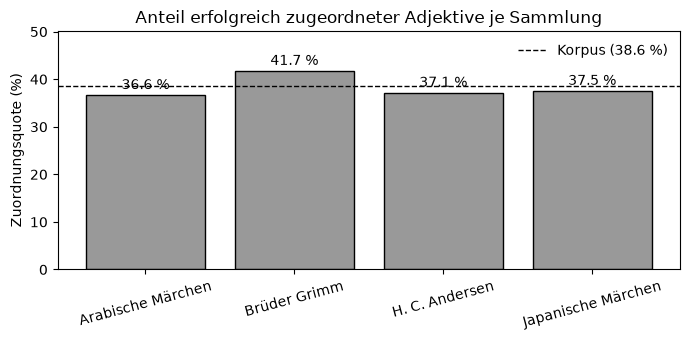

In [5]:
#Zuordnungsquote je Sammlung (Anteil zugeordneter an allen Adjektivbelegen)
quote = (100 * zugeordnet.groupby("sammlung").size()
         / df_zuordnungen.groupby("sammlung").size()).loc[SAMMLUNGEN]
korpus_wert = 100 * len(zugeordnet) / len(df_zuordnungen)
print(quote.round(1))
print("Korpus:", round(korpus_wert, 1))

fig, ax = plt.subplots(figsize=(7, 3.5))
balken = ax.bar(quote.index, quote.values, color="0.6", edgecolor="black")
ax.axhline(korpus_wert, color="black", linestyle="--", linewidth=1,
           label="Korpus (" + str(round(korpus_wert, 1)) + " %)")
ax.bar_label(balken, fmt="%.1f %%", padding=2)
ax.set_ylabel("Zuordnungsquote (%)")
ax.set_ylim(0, max(quote.max(), korpus_wert) * 1.2)
ax.set_title("Anteil erfolgreich zugeordneter Adjektive je Sammlung")
ax.legend(frameon=False)
plt.xticks(rotation=15)
plt.tight_layout()
fig.savefig(AUSGABE / "abbildung2_zuordnungsquote.png", dpi=300, bbox_inches="tight")
plt.show()

### 6.2 Zuordnungen der Adjektivbelege

**Tabelle 2:** Adjektivkonstruktionen und Zuordnungsquoten

In [6]:
#Konstruktion je Beleg; ohne Bezugswort ist das Feld leer
konstruktion = df_zuordnungen["konstruktion"].fillna("ohne Bezugswort")
tabelle2 = pd.crosstab(konstruktion, df_zuordnungen["status"])
tabelle2["belege"] = tabelle2["zugeordnet"] + tabelle2["offen"]
tabelle2["anteil_%"] = (100 * tabelle2["belege"] / tabelle2["belege"].sum()).round(1)
tabelle2["quote_%"] = (100 * tabelle2["zugeordnet"] / tabelle2["belege"]).round(1)
tabelle2 = tabelle2.sort_values("belege", ascending=False)
tabelle2[["belege", "anteil_%", "zugeordnet", "quote_%"]]

status,belege,anteil_%,zugeordnet,quote_%
konstruktion,,,,
attributiv,6170,56.0,2093,33.9
praedikativ/adverbial,3562,32.3,1976,55.5
ohne Bezugswort,708,6.4,0,0.0
objektspraedikativ,407,3.7,86,21.1
relativsatz,175,1.6,99,56.6


**Tabelle 3:** Gründe nicht zugeordneter Belege

In [7]:
#Anteil der Gründe an allen offenen Belegen je Sammlung (%)
gruende = pd.crosstab(offen["grund_offen"], offen["sammlung"], margins=True, margins_name="Korpus")
tabelle3 = (100 * gruende / gruende.loc["Korpus"]).round(1).drop(index="Korpus")
tabelle3 = tabelle3.sort_values("Korpus", ascending=False)
display(tabelle3)
print("Offene Fälle gesamt:")
gruende.loc["Korpus"]

sammlung,Arabische Märchen,Brüder Grimm,H. C. Andersen,Japanische Märchen,Korpus
grund_offen,,,,,
bezugswort_keine_figur,73.7,68.4,72.5,73.8,71.7
pronomen,10.6,16.5,13.6,10.8,13.3
kein_bezugswort,10.5,12.3,8.4,9.9,10.5
adverbial_ohne_figurenbezug,5.1,2.8,5.5,5.5,4.5


Offene Fälle gesamt:


sammlung
Arabische Märchen     1907
Brüder Grimm          2155
H. C. Andersen        1787
Japanische Märchen     919
Korpus                6768
Name: Korpus, dtype: int64

### 6.3 Figureninventar

Verdichtung der NER-Rohformen zu kanonischen Figuren.

In [8]:
n_roh = len(daten["figuren_ner_haeufigkeit_gesamt"])
n_kan = len(daten["figuren_kanonisch_gesamt"])
print("Korpusweit:", n_roh, "Rohformen ->", n_kan, "kanonische Figuren | Reduktion:",
      prozent(n_roh - n_kan, n_roh), "%")

#je Sammlung über die Märchenstatistik (innerhalb der einzelnen Märchen gezählt)
verdichtung = df_maerchen.groupby("sammlung")[["ner_rohformen", "figuren"]].sum()
verdichtung["reduktion_%"] = (100 * (1 - verdichtung["figuren"] / verdichtung["ner_rohformen"])).round(1)
verdichtung

Korpusweit: 1332 Rohformen -> 1090 kanonische Figuren | Reduktion: 18.2 %


,ner_rohformen,figuren,reduktion_%
sammlung,,,
Arabische Märchen,738,599,18.8
Brüder Grimm,1121,993,11.4
H. C. Andersen,565,492,12.9
Japanische Märchen,375,316,15.7


**Tabelle 4:** Figureninventar je Sammlung

In [9]:
#In wie vielen Märchen kommt jede Figur vor (je Sammlung und korpusweit)?
maerchen_je_figur = defaultdict(Counter)
maerchen_je_figur_korpus = Counter()
sammlungen_je_figur = defaultdict(set)
for m in daten["pro_maerchen"]:
    for figur in m["figuren_kanonisch"]:
        maerchen_je_figur[m["sammlung"]][figur] += 1
        maerchen_je_figur_korpus[figur] += 1
        sammlungen_je_figur[figur].add(m["sammlung"])


def inventar(alle, mit_profil, verbreitung, je_maerchen):
    #Eine Zeile von Tabelle 4
    ohne = [f for f in alle if f not in mit_profil]
    return {
        "figuren": len(alle),
        "je_maerchen_mittel": round(je_maerchen.mean(), 1),
        "je_maerchen_median": je_maerchen.median(),
        "nur_in_einem_maerchen_%": prozent(sum(1 for n in verbreitung.values() if n == 1), len(verbreitung)),
        "ohne_zugeordnetes_adjektiv_%": prozent(len(ohne), len(alle)),
    }


zeilen = {}
for s in SAMMLUNGEN:
    zeilen[s] = inventar(daten["figuren_kanonisch_pro_sammlung"][s],
                         daten["figuren_profil_pro_sammlung"][s],
                         maerchen_je_figur[s],
                         df_maerchen.loc[df_maerchen["sammlung"] == s, "figuren"])
zeilen["Korpus"] = inventar(daten["figuren_kanonisch_gesamt"],
                            daten["figuren_profil_aggregiert"],
                            maerchen_je_figur_korpus,
                            df_maerchen["figuren"])
tabelle4 = pd.DataFrame(zeilen).T
tabelle4

,figuren,je_maerchen_mittel,je_maerchen_median,nur_in_einem_maerchen_%,ohne_zugeordnetes_adjektiv_%
Arabische Märchen,382.0,74.9,68.0,75.1,56.0
Brüder Grimm,438.0,22.1,21.0,67.1,46.8
H. C. Andersen,341.0,44.7,46.0,83.3,49.6
Japanische Märchen,215.0,19.8,18.0,79.1,40.9
Korpus,1090.0,30.0,23.5,72.8,49.5


**Tabelle 5:** Top-10-Figuren- und Rollennennungen

Gezählt werden die Nennungen je Aggregationsschlüssel in den einzelnen Märchen, also vor der korpusweiten Zusammenführung.

In [10]:
#Nennungen je Aggregationsschlüssel in den einzelnen Märchen (Feld "schluessel_formen")
nennungen = defaultdict(Counter)
for m in daten["pro_maerchen"]:
    for schluessel, formen in m["schluessel_formen"].items():
        nennungen[m["sammlung"]][schluessel] += sum(formen.values())

tabelle5 = pd.DataFrame({
    s: [name + " (" + str(n) + ")" for name, n in nennungen[s].most_common(10)]
    for s in SAMMLUNGEN
})
tabelle5.index = range(1, 11)
tabelle5

,Arabische Märchen,Brüder Grimm,H. C. Andersen,Japanische Märchen
1,prinz (159),könig (230),gerda (99),mann (61)
2,sultan (127),kind (126),kay (59),frau (57)
3,könig (102),mann (121),mädchen (55),urashima (33)
4,prinz achmed (89),vater (112),knabe (52),dachs (31)
5,ali baba (84),frau (103),blume (52),kaiser (29)
6,frau (73),mädchen (85),könig (51),hase (29)
7,vater (73),königin (65),kaiser (50),sperling (27)
8,bruder (69),soldat (64),soldat (46),kind (25)
9,fischer (58),tochter (61),nachtigall (43),vater (21)
10,geist (56),schneider (61),vogel (40),gott (21)


Häufigste Figuren korpusweit und Verbreitung über Märchen und Sammlungen.

In [11]:
#Häufigste Figuren korpusweit (Nennungen nach der Zusammenführung)
print("Häufigste Figuren korpusweit:", Counter(daten["figuren_kanonisch_gesamt"]).most_common(4))

n_figuren = len(maerchen_je_figur_korpus)
n_einmal = sum(1 for n in maerchen_je_figur_korpus.values() if n == 1)
print("Figuren nur in einem Märchen:", n_einmal, "von", n_figuren, "|", prozent(n_einmal, n_figuren), "%")
print("Figuren in mehr als einer Sammlung:", sum(1 for s in sammlungen_je_figur.values() if len(s) > 1))

#Am weitesten verbreitete Figuren
verbreitet = pd.DataFrame([
    {"figur": f, "maerchen": n, "sammlungen": len(sammlungen_je_figur[f]),
     "fehlt_in": ", ".join(s for s in SAMMLUNGEN if s not in sammlungen_je_figur[f])}
    for f, n in maerchen_je_figur_korpus.most_common(15)
])
verbreitet.index = range(1, len(verbreitet) + 1)
verbreitet

Häufigste Figuren korpusweit: [('König', 384), ('Mann', 292), ('Frau', 269), ('Vater', 220)]
Figuren nur in einem Märchen: 794 von 1090 | 72.8 %
Figuren in mehr als einer Sammlung: 186


,figur,maerchen,sammlungen,fehlt_in
1,Mann,51,4,
2,Frau,48,4,
3,Kind,43,4,
4,Gott,40,4,
5,König,38,3,Japanische Märchen
6,Vater,35,4,
7,Mädchen,31,4,
8,Sohn,29,4,
9,Mutter,29,4,
10,Leute,29,4,


Figuren ohne zugeordnetes Adjektiv.

In [12]:
#Figuren ohne ein einziges zugeordnetes Adjektiv
zeilen = {}
ohne_je_ebene = {}
for s in SAMMLUNGEN + ["Korpus"]:
    if s == "Korpus":
        alle, mit = daten["figuren_kanonisch_gesamt"], daten["figuren_profil_aggregiert"]
    else:
        alle, mit = daten["figuren_kanonisch_pro_sammlung"][s], daten["figuren_profil_pro_sammlung"][s]
    ohne = {f: n for f, n in alle.items() if f not in mit}
    ohne_je_ebene[s] = ohne
    zeilen[s] = {"figuren": len(alle), "ohne_adjektiv": len(ohne),
                 "anteil_ohne_%": prozent(len(ohne), len(alle)),
                 "nennungen_ohne_adjektiv_%": prozent(sum(ohne.values()), sum(alle.values()))}
display(pd.DataFrame(zeilen).T)

print("Meistgenannte Figuren ohne Adjektiv (korpusweit):")
print(Counter(ohne_je_ebene["Korpus"]).most_common(5))

,figuren,ohne_adjektiv,anteil_ohne_%,nennungen_ohne_adjektiv_%
Arabische Märchen,382.0,214.0,56.0,20.1
Brüder Grimm,438.0,205.0,46.8,10.4
H. C. Andersen,341.0,169.0,49.6,16.6
Japanische Märchen,215.0,88.0,40.9,15.8
Korpus,1090.0,540.0,49.5,12.3


Meistgenannte Figuren ohne Adjektiv (korpusweit):
[('Prinz Achmed', 89), ('Prinz Hussain', 29), ('Prinz Aly', 23), ('Fee Pari', 21), ('Prinzessin Nurunnihar', 20)]


### 6.4 Figurenprofile

Die Adjektive werden in ihrer Normform gezählt (Feld `adjektive_norm_haeufigkeit`).

In [13]:
def adjektiv_haeufigkeiten(profil):
    #Adjektive einer Figur in Normform als Liste von (Normform, Anzahl), absteigend
    return [(e["normform"], e["anzahl"]) for e in profil["adjektive_norm_haeufigkeit"]]


profile_korpus = daten["figuren_profil_aggregiert"]
normformen = {a for p in profile_korpus.values() for a, _ in adjektiv_haeufigkeiten(p)}
print("Figuren mit Profil:", len(profile_korpus),
      "| Belege:", sum(p["gesamt_nennungen"] for p in profile_korpus.values()),
      "| verschiedene Adjektive (Normformen):", len(normformen))
print("Figuren mit mindestens 10 Belegen (korpusweit):",
      sum(1 for p in profile_korpus.values() if p["gesamt_nennungen"] >= 10))

Figuren mit Profil: 550 | Belege: 4254 | verschiedene Adjektive (Normformen): 901
Figuren mit mindestens 10 Belegen (korpusweit): 96


**Tabelle 6:** Adjektivprofile je Sammlung

In [14]:
def profil_kennzahlen(profile):
    #Eine Zeile von Tabelle 6
    belege = sorted((p["gesamt_nennungen"] for p in profile.values()), reverse=True)
    typen = {a for p in profile.values() for a, _ in adjektiv_haeufigkeiten(p)}
    return {
        "figuren_mit_profil": len(belege),
        "belege": sum(belege),
        "verschiedene_adjektive": len(typen),
        "belege_je_figur_median": pd.Series(belege).median(),
        "nur_ein_beleg_%": prozent(sum(1 for n in belege if n == 1), len(belege)),
        "anteil_top10_%": prozent(sum(belege[:10]), sum(belege)),
    }


zeilen = {s: profil_kennzahlen(daten["figuren_profil_pro_sammlung"][s]) for s in SAMMLUNGEN}
zeilen["Korpus"] = profil_kennzahlen(daten["figuren_profil_aggregiert"])
tabelle6 = pd.DataFrame(zeilen).T
tabelle6

,figuren_mit_profil,belege,verschiedene_adjektive,belege_je_figur_median,nur_ein_beleg_%,anteil_top10_%
Arabische Märchen,168.0,1103.0,447.0,2.0,41.7,38.7
Brüder Grimm,233.0,1543.0,374.0,2.0,34.8,37.5
H. C. Andersen,172.0,1056.0,265.0,2.0,44.8,46.3
Japanische Märchen,127.0,552.0,298.0,2.0,41.7,43.1
Korpus,550.0,4254.0,901.0,2.0,40.9,27.8


**Abbildung 3:** Adjektivbelege und verschiedene Adjektive je Figur

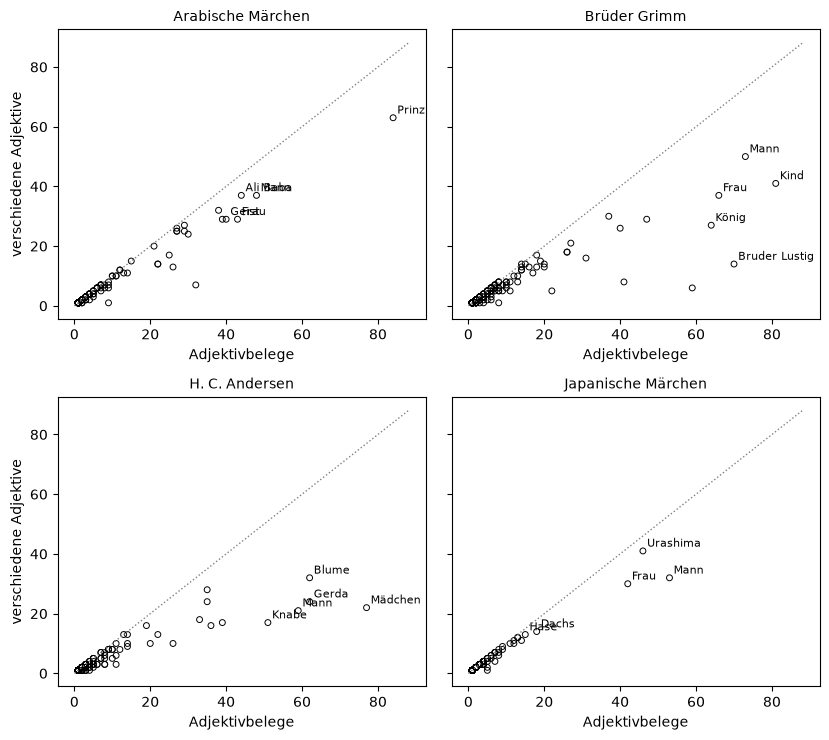

In [15]:
#Je Figur: Zahl der Adjektivbelege und Zahl der verschiedenen Adjektive
df_profile = pd.DataFrame([
    {"sammlung": s, "figur": figur,
     "belege": p["gesamt_nennungen"],
     "verschiedene_adjektive": len(adjektiv_haeufigkeiten(p))}
    for s in SAMMLUNGEN
    for figur, p in daten["figuren_profil_pro_sammlung"][s].items()
])

fig, achsen = plt.subplots(2, 2, figsize=(8.5, 7.5), sharex=True, sharey=True)
grenze = df_profile["belege"].max() * 1.05
for ax, s in zip(achsen.flat, SAMMLUNGEN):
    d = df_profile[df_profile["sammlung"] == s]
    ax.scatter(d["belege"], d["verschiedene_adjektive"],
               s=18, facecolors="none", edgecolors="black", linewidths=0.7)
    #gepunktete Diagonale: jedes Adjektiv genau einmal belegt
    ax.plot([0, grenze], [0, grenze], color="0.5", linestyle=":", linewidth=1)
    #die fünf Figuren mit den meisten Belegen beschriften
    for _, z in d.nlargest(5, "belege").iterrows():
        ax.annotate(z["figur"], (z["belege"], z["verschiedene_adjektive"]),
                    fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.set_title(s, fontsize=10)
    ax.set_xlabel("Adjektivbelege")
    ax.tick_params(labelbottom=True)
for ax in achsen[:, 0]:
    ax.set_ylabel("verschiedene Adjektive")
plt.tight_layout()
fig.savefig(AUSGABE / "abbildung3_profile.png", dpi=300, bbox_inches="tight")
plt.show()

**Tabelle 7:** Top-10-Figuren mit Top-5-Adjektiven (Brüder Grimm)

In [16]:
def top_adjektive_tabelle(profile, n_figuren=10, n_adjektive=5):
    #Die Figuren mit den meisten Belegen und ihre häufigsten Adjektive
    rangfolge = sorted(profile.items(), key=lambda x: -x[1]["gesamt_nennungen"])[:n_figuren]
    zeilen = []
    for figur, p in rangfolge:
        haeufig = adjektiv_haeufigkeiten(p)[:n_adjektive]
        zeilen.append({
            "figur": figur,
            "belege": p["gesamt_nennungen"],
            "maerchen": p["anzahl_maerchen"],
            "haeufigste_adjektive": ", ".join(a + " (" + str(n) + ")" for a, n in haeufig),
        })
    tabelle = pd.DataFrame(zeilen)
    tabelle.index = range(1, len(tabelle) + 1)
    return tabelle


pd.set_option("display.max_colwidth", 120)
top_adjektive_tabelle(daten["figuren_profil_pro_sammlung"]["Brüder Grimm"])

,figur,belege,maerchen,haeufigste_adjektive
1,Kind,81,18,"lieb (9), tot (7), schön (6), arm (5), müde (4)"
2,Mann,73,22,"klein (7), arm (5), alte (4), fremd (4), gut (3)"
3,Bruder Lustig,70,1,"lustig (56), froh (2), übrig (1), dumm (1), wunderlich (1)"
4,Frau,66,20,"lieb (10), alte (10), schön (5), weis (3), garstig (2)"
5,König,64,12,"jung (12), alte (9), krank (6), zornig (5), lieb (4)"
6,Petrus,59,2,"heilig (54), geschwind (1), langsam (1), gesund (1), schön (1)"
7,Mädchen,47,11,"schön (6), gut (5), arm (4), bedeckt (3), schlecht (2)"
8,Johannes,41,1,"treu (17), getreu (15), getreuester (4), getreust (1), schnell (1)"
9,Tochter,40,10,"schön (8), häßlich (4), recht (3), gut (2), klug (2)"
10,Soldat,37,8,"abgedankt (4), gut (3), verabschiedet (2), arm (2), lebendig (1)"


**Tabelle 8:** Top-10-Figuren mit Top-5-Adjektiven (H. C. Andersen)

In [17]:
top_adjektive_tabelle(daten["figuren_profil_pro_sammlung"]["H. C. Andersen"])

,figur,belege,maerchen,haeufigste_adjektive
1,Mädchen,77,7,"klein (45), gut (6), arm (5), jung (2), niedlich (2)"
2,Blume,62,7,"schön (6), prächtig (5), herrlich (4), anderer (4), arm (3)"
3,Gerda,62,1,"klein (36), lieb (2), lebendig (2), groß (2), häßlich (1)"
4,Mann,59,4,"alte (35), einsam (2), gut (2), jung (2), klein (2)"
5,Knabe,51,4,"klein (33), lang (2), tot (2), frisch (1), plötzlich (1)"
6,Frau,39,6,"alte (19), jung (4), schön (2), klug (1), lebensfroh (1)"
7,Kay,36,1,"klein (18), tot (2), steif (2), still (2), arm (1)"
8,Elise,35,1,"schön (3), unschuldig (3), klein (2), arm (2), ängstlich (2)"
9,Däumelieschen,35,1,"_ (3), klein (3), arm (3), leicht (2), anderer (2)"
10,Vogel,33,6,"klein (8), tot (4), groß (3), schön (3), künstlich (2)"


**Tabelle 9:** Top-10-Figuren mit Top-5-Adjektiven (Arabische Märchen)

In [18]:
top_adjektive_tabelle(daten["figuren_profil_pro_sammlung"]["Arabische Märchen"])

,figur,belege,maerchen,haeufigste_adjektive
1,Prinz,84,2,"lang (4), alte (3), glücklich (3), anderer (3), voll (2)"
2,Mann,48,7,"tot (3), weis (3), jung (3), bereit (2), sanft (2)"
3,Ali Baba,44,1,"genau (2), sorgfältig (2), ungeduldig (2), reich (2), gut (2)"
4,Frau,43,5,"schön (7), gut (5), gnädig (2), anderer (2), lang (2)"
5,Geist,40,3,"bös (6), treu (4), lang (3), schlimm (2), liebevoll (1)"
6,Mädchen,39,6,"schön (7), fremd (2), zart (2), reizend (2), lieblich (2)"
7,König,38,5,"groß (3), reich (2), mächtig (2), wahrlich (2), verwundert (2)"
8,Gott,32,6,"allmächtig (18), erhaben (7), hoher (3), groß (1), gewaltig (1)"
9,Fischer,30,2,"still (3), traurig (2), zufrieden (2), rasch (2), gut (2)"
10,Perser,29,1,"leise (3), heimlich (2), glücklich (2), weis (1), bestürzt (1)"


**Tabelle 10:** Top-10-Figuren mit Top-5-Adjektiven (Japanische Märchen)

In [19]:
top_adjektive_tabelle(daten["figuren_profil_pro_sammlung"]["Japanische Märchen"])

,figur,belege,maerchen,haeufigste_adjektive
1,Mann,53,11,"alte (11), jung (8), zufrieden (3), tapfer (2), brav (2)"
2,Urashima,46,1,"ängstlich (3), urashima (2), bedenklich (2), langsam (2), empört (1)"
3,Frau,42,5,"alte (4), lieb (3), bös (3), schön (3), ermordet (2)"
4,Dachs,18,1,"tot (4), alte (2), nachdenklich (1), einfältig (1), frei (1)"
5,Hase,15,1,"weiß (3), gut (1), flink (1), scheinbar (1), hilfsbereit (1)"
6,Sperling,14,1,"klein (3), dankbar (2), jung (1), schnell (1), hübsch (1)"
7,Steinhauer,13,1,"glücklich (2), losschlug (1), verwundert (1), ruhig (1), erfreut (1)"
8,Landmann,13,1,"groß (2), plötzlich (1), verwundert (1), lustig (1), hocherfreut (1)"
9,Mädchen,12,2,"schön (2), groß (2), befindlich (1), untröstlich (1), jung (1)"
10,Kind,12,4,"anderer (2), überdrüssig (1), arm (1), ruhend (1), tüchtig (1)"


**Tabelle 11:** Top-10-Figuren mit Top-5-Adjektiven (Korpus)

In [20]:
top_adjektive_tabelle(daten["figuren_profil_aggregiert"])

,figur,belege,maerchen,haeufigste_adjektive
1,Mann,233,44,"alte (52), jung (15), klein (9), tot (6), gut (6)"
2,Frau,190,36,"alte (33), schön (17), lieb (13), gut (7), anderer (4)"
3,Mädchen,175,26,"klein (45), schön (16), gut (11), arm (10), fremd (4)"
4,Kind,112,31,"lieb (11), arm (10), schön (7), tot (7), müde (4)"
5,König,109,19,"jung (13), alte (10), krank (6), lieb (5), zornig (5)"
6,Prinz,99,6,"lang (4), alte (3), glücklich (3), anderer (3), jung (3)"
7,Bruder Lustig,70,1,"lustig (56), froh (2), übrig (1), dumm (1), wunderlich (1)"
8,Blume,68,10,"schön (7), prächtig (5), groß (4), herrlich (4), anderer (4)"
9,Bruder,63,12,"lieb (10), jung (7), anderer (3), reich (3), alte (2)"
10,Gerda,62,1,"klein (36), lieb (2), lebendig (2), groß (2), häßlich (1)"
